In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data=pd.read_csv('/content/drive/MyDrive/Final year project/Crop_recommendation.csv')
crop=data


In [ ]:
crop.tail(10)

,N,P,K,temperature,humidity,ph,rainfall,label
2190,103,40,30,27.309018,55.196224,6.348316,141.483164,coffee
2191,118,31,34,27.548230,62.881792,6.123796,181.417081,coffee
2192,106,21,35,25.627355,57.041511,7.428524,188.550654,coffee
2193,116,38,34,23.292503,50.045570,6.020947,183.468585,coffee
2194,97,35,26,24.914610,53.741447,6.334610,166.254931,coffee
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,coffee
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,coffee
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,coffee
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,coffee
2199,104,18,30,23.603016,60.396475,6.779833,140.937041,coffee


In [ ]:
crop.describe(include='all')

,N,P,K,temperature,humidity,ph,rainfall,label
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,rice
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655,NaN
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389,NaN
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267,NaN
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686,NaN
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624,NaN
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508,NaN


In [ ]:
crop.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

In [ ]:

print("Number of various crops: ", len(crop['label'].unique()))
print("List of crops: ", crop['label'].unique())

Number of various crops:  22
List of crops:  ['rice' 'maize' 'chickpea' 'kidneybeans' 'pigeonpeas' 'mothbeans'
 'mungbean' 'blackgram' 'lentil' 'pomegranate' 'banana' 'mango' 'grapes'
 'watermelon' 'muskmelon' 'apple' 'orange' 'papaya' 'coconut' 'cotton'
 'jute' 'coffee']


In [ ]:
crops_name=crop['label'].unique().sort()
crops_name

In [ ]:
crop_summary = pd.pivot_table(crop,index=['label'],aggfunc='mean')
crop_summary.head(22)

,K,N,P,humidity,ph,rainfall,temperature
label,,,,,,,
apple,199.89,20.80,134.22,92.333383,5.929663,112.654779,22.630942
banana,50.05,100.23,82.01,80.358123,5.983893,104.626980,27.376798
blackgram,19.24,40.02,67.47,65.118426,7.133952,67.884151,29.973340
chickpea,79.92,40.09,67.79,16.860439,7.336957,80.058977,18.872847
coconut,30.59,21.98,16.93,94.844272,5.976562,175.686646,27.409892
coffee,29.94,101.20,28.74,58.869846,6.790308,158.066295,25.540477
cotton,19.56,117.77,46.24,79.843474,6.912675,80.398043,23.988958
grapes,200.11,23.18,132.53,81.875228,6.025937,69.611829,23.849575
jute,39.99,78.40,46.86,79.639864,6.732778,174.792798,24.958376


<ipython-input-9-5d87fbfb1798>:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  sns.heatmap(crop.corr(), annot=True,cmap='Greys',vmin=-1, vmax=1 )


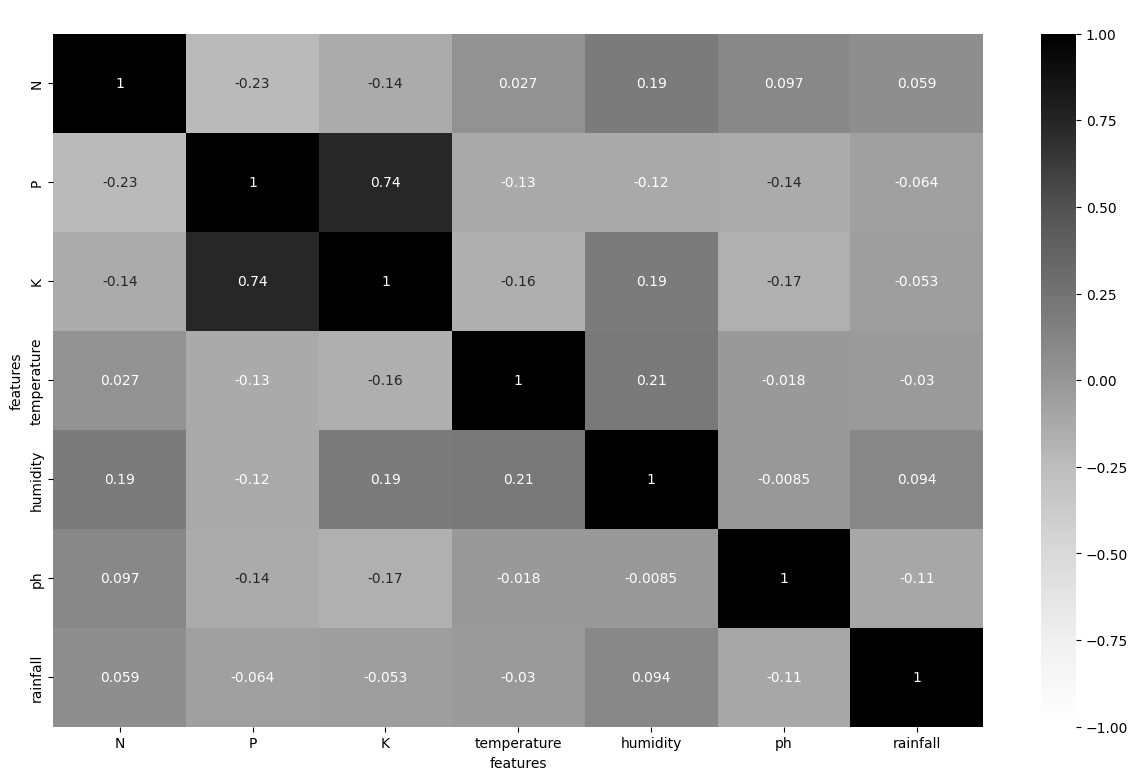

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(15, 9))
sns.heatmap(crop.corr(), annot=True,cmap='Greys',vmin=-1, vmax=1 )
ax.set(xlabel='features')
ax.set(ylabel='features')

plt.title('Correlation between different features', fontsize = 15, c='white')
plt.show()

In [ ]:
'''from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test) '''

'from sklearn.preprocessing import MinMaxScaler\nscaler = MinMaxScaler()\nX_train_scale = scaler.fit_transform(X_train)\nX_test_scale = scaler.transform(X_test) '

**Scaling**

In [ ]:
a=[598.552,0.000,0.000,20.48349,64.876363]
scale(a)

Data Visualization

Model Building


In [ ]:
X = crop.drop('label', axis=1)
y = crop['label']
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [ ]:
import h5py
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

def random_forest_logistic_regression_ensemble(X, y, n_estimators=10, max_depth=None, max_features=None, random_state=None):
    """
    Creates an ensemble of decision trees using random forest and a logistic regression model for classification.
    
    Parameters:
    X (array-like): The feature matrix.
    y (array-like): The target vector.
    n_estimators (int): The number of trees in the random forest.
    max_depth (int): The maximum depth of each tree. If None, the tree is fully grown.
    max_features (int): The maximum number of features to consider when splitting each node. If None, use all features.
    random_state (int): The random state used for the random forest and logistic regression.
    
    Returns:
    model (object): The fitted random forest and logistic regression ensemble model.
    """
    
    # Create random forest model for predicting possible outcome results
    rf = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, max_features=max_features, random_state=random_state)
    rf.fit(X, y)
    
    # Combine possible outcome results predictions from random forest using logistic regression 
    X_pred = rf.predict_proba(X)
    
    # Fit logistic regression model on combined predictions based on previous possible outcomes
    lr = LogisticRegression(random_state=random_state,max_iter=1000)
    lr.fit(X_pred, y)
    
    # Combine random forest and logistic regression into single model object
    model = {
        "random_forest": rf,
        "logistic_regression": lr,
        "n_estimators": n_estimators,
        "max_depth": max_depth,
        "max_features": max_features,
        "random_state": random_state
    }
    
    return model
import numpy as np
# Train the model
'''X, y = load_iris(return_X_y=True)
model = random_forest_logistic_regression_ensemble(X, y, n_estimators=100, max_depth=5, max_features='sqrt', random_state=42)'''


"X, y = load_iris(return_X_y=True)\nmodel = random_forest_logistic_regression_ensemble(X, y, n_estimators=100, max_depth=5, max_features='sqrt', random_state=42)"

In [ ]:
from sklearn import metrics
def predict(model, X):
    # Use random forest to get predictions for new input
    rf = model["random_forest"]
    X_pred = rf.predict_proba(X)
    
    
    # Use logistic regression to predict final class labels
    lr = model["logistic_regression"]
    y_pred = lr.predict(X_pred)
    
    return y_pred

model = random_forest_logistic_regression_ensemble(X_train, y_train,  n_estimators=100, max_depth=5, max_features=4,random_state=42)
y_pred=predict(model,X_test)
cm=metrics.accuracy_score(y_test, y_pred)
print(cm)




0.9409090909090909


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))
import matplotlib.pyplot as plt


              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        18
      banana       0.91      1.00      0.95        21
   blackgram       0.94      1.00      0.97        17
    chickpea       1.00      1.00      1.00        21
     coconut       1.00      1.00      1.00        23
      coffee       1.00      0.96      0.98        26
      cotton       0.95      1.00      0.98        20
      grapes       1.00      1.00      1.00        14
        jute       0.34      1.00      0.51        10
 kidneybeans       1.00      1.00      1.00        22
      lentil       1.00      1.00      1.00        13
       maize       0.93      0.93      0.93        14
       mango       1.00      0.93      0.96        28
   mothbeans       1.00      0.93      0.97        15
    mungbean       1.00      1.00      1.00        17
   muskmelon       1.00      1.00      1.00        24
      orange       1.00      1.00      1.00        19
      papaya       1.00    

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


<Figure size 1000x1000 with 0 Axes>

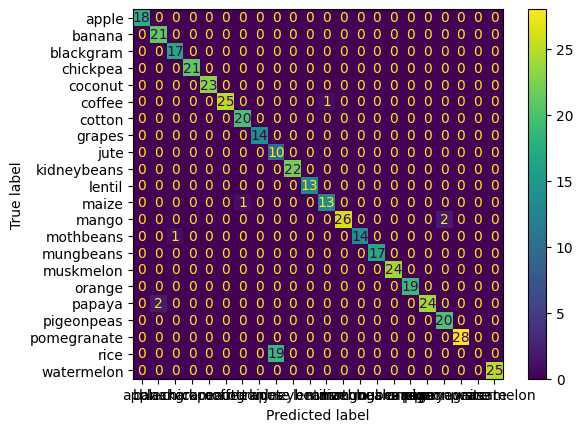

In [ ]:
confusion_matrix = metrics.confusion_matrix(y_test, y_pred)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = ['apple','banana','blackgram','chickpea','coconut','coffee','cotton','grapes','jute','kidneybeans','lentil','maize','mango','mothbeans','mungbeans','muskmelon','orange','papaya','pigeonpeas','pomegranate','rice',])
cm_display.plot()
plt.show()

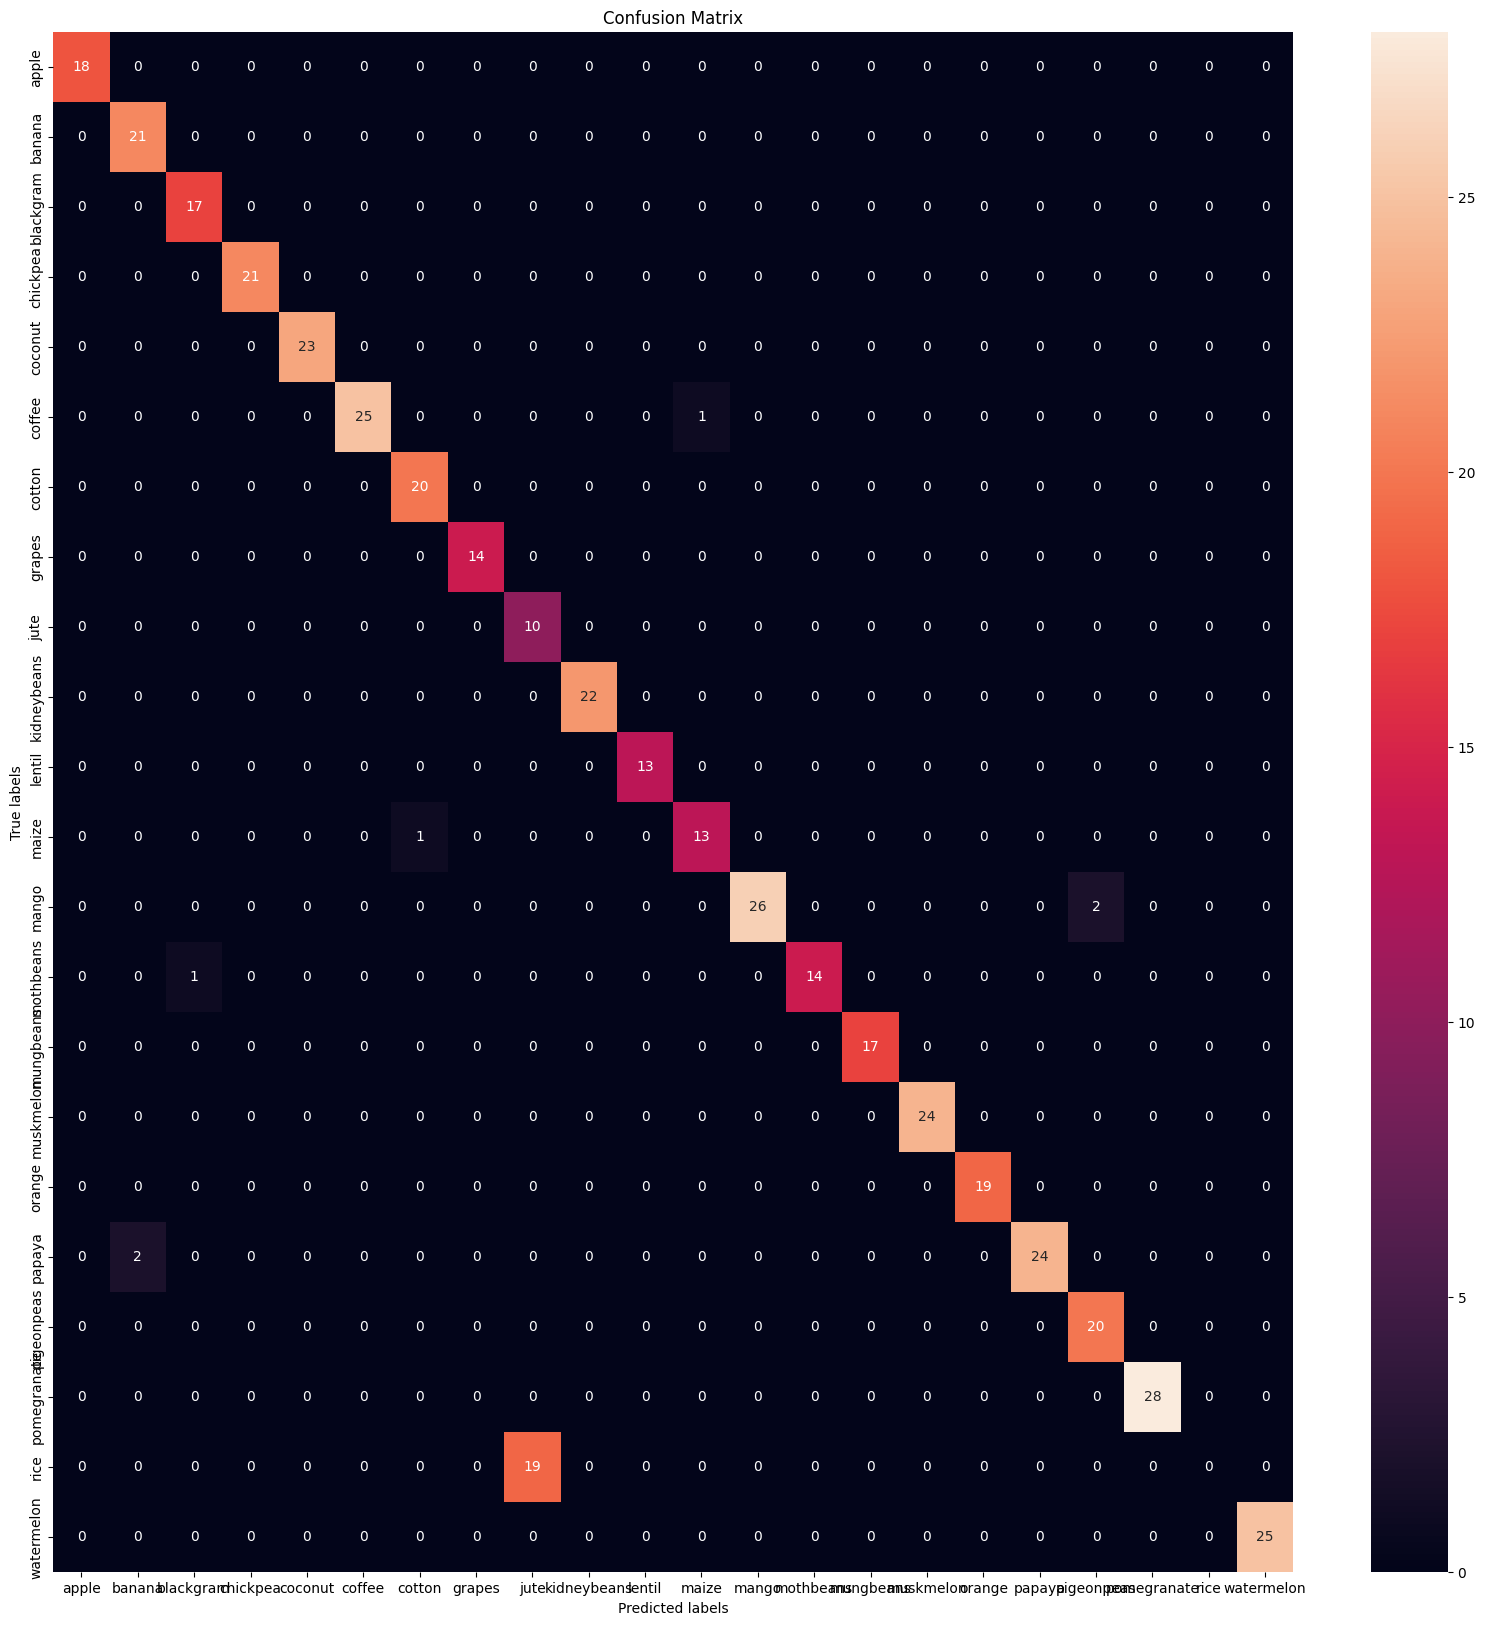

In [ ]:
fig, ax = plt.subplots(figsize=(20,20))
sns.heatmap(confusion_matrix, annot=True, fmt='g', ax=ax);  #annot=True to annotate cells, ftm='g' to disable scientific notation

# labels, title and ticks
ax.set_xlabel('Predicted labels');ax.set_ylabel('True labels'); 
ax.set_title('Confusion Matrix'); 
ax.xaxis.set_ticklabels(['apple','banana','blackgram','chickpea','coconut','coffee','cotton','grapes','jute','kidneybeans','lentil','maize','mango','mothbeans','mungbeans','muskmelon','orange','papaya','pigeonpeas','pomegranate','rice','watermelon']); ax.yaxis.set_ticklabels(['apple','banana','blackgram','chickpea','coconut','coffee','cotton','grapes','jute','kidneybeans','lentil','maize','mango','mothbeans','mungbeans','muskmelon','orange','papaya','pigeonpeas','pomegranate','rice','watermelon']);

In [ ]:
confusion_matrix

array([[18,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0, 21,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0,  0, 17,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0,  0,  0, 21,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0, 23,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0, 25,  0,  0,  0,  0,  0,  1,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0, 20,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0, 14,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0, 10,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0, 22,  0,  0,

In [ ]:
import joblib
joblib.dump(model,'Ensemble_Random_forest.joblib')

['Ensemble_Random_forest.joblib']

Real value giving and taking output

In [ ]:
N,P,K,Temp,Hum,ph,rainfall=2 ##value intialization

In [ ]:
import joblib
import warnings
warnings.filterwarnings("ignore",category=UserWarning)
#model1=joblib.load("/content/Ensemble_Random_forest.joblib") ##importing the model_datas
test_data=[[57, 68, 81, 17.179744, 17.304, 8.1,72]] # dataframe creation
def predict(model, X):
    # Use random forest to get predictions for new input
    rf = model["random_forest"]
    X_pred = rf.predict_proba(X)
    print(X_pred)
    # Use logistic regression to predict final class labels
    lr = model["logistic_regression"]
    
    y_pred = lr.predict(X_pred)
    
    return y_pred
result=0
result= predict(model,test_data)


print("Best Crop for this parameter will be : "+ result)

[[0.00000000e+00 5.33707865e-03 0.00000000e+00 9.68936202e-01
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  3.93258427e-04 9.63454935e-03 0.00000000e+00 0.00000000e+00
  1.54741929e-02 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 5.61797753e-05
  1.68539326e-04 0.00000000e+00]]
['chickpea']
['Best Crop for this parameter will be : chickpea']


end of model creation , below here are just for reference

In [ ]:

from sklearn.ensemble import RandomForestClassifier

tree_clf = RandomForestClassifier(n_estimators=100, max_depth=5, max_features=4,random_state=42)

tree_clf.fit(X_train,y_train)
from sklearn import metrics
y_pred=tree_clf.predict(X_test)
cm=metrics.accuracy_score(y_test, y_pred)
cm

0.9636363636363636

In [ ]:
import joblib
joblib.dump(tree_clf,'Random_forest.joblib')

['Random_forest.joblib']

In [ ]:
from sklearn import metrics
y_pred=tree_clf.predict(X_test)
cm=metrics.accuracy_score(y_test, y_pred)
cm

0.9573863636363636

In [ ]:
y_pred1=tree_clf.predict([[90, 42, 43, 20.879744, 75, 5.5,220]])
y_pred1

/usr/local/lib/python3.8/dist-packages/sklearn/base.py:450: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


array(['rice'], dtype=object)

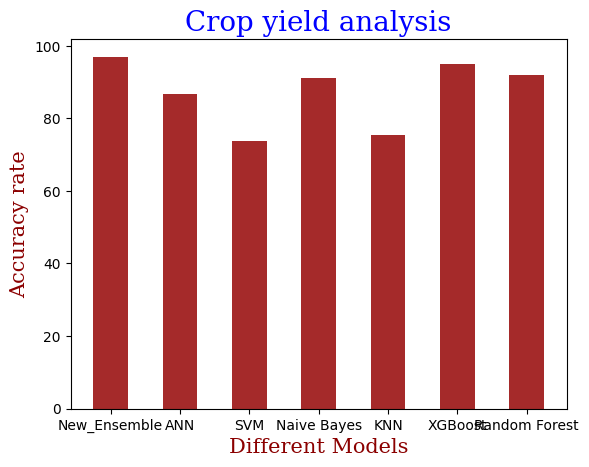

In [ ]:
xpoints = np.array(['New_Ensemble','ANN','SVM','Naive Bayes','KNN','XGBoost','Random Forest'])
ypoints = np.array([97,86.8,73.8,91.11,75.5,95,92])

plt.bar(xpoints,ypoints,color='brown',width=0.5)
font1 = {'family':'serif','color':'blue','size':20}
font2 = {'family':'serif','color':'darkred','size':15}

plt.title("Crop yield analysis", fontdict = font1)

plt.xlabel("Different Models",fontdict=font2)
plt.ylabel("Accuracy rate",fontdict=font2)
plt.show()